# GIAI ĐOẠN 1: KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS - EDA)
## Đề tài: Phân khúc khách hàng bán lẻ trực tuyến bằng RFM và Học máy (Online Retail II)

Tập notebook này tập trung hoàn toàn vào việc khảo sát, khám phá cấu trúc, phân phối, tương quan và các đặc tính thống kê cơ bản của dữ liệu giao dịch bán lẻ thô.

---
### Mục tiêu chính:
1. **Khảo sát cấu trúc & thuộc tính:** Kích thước dữ liệu, kiểu dữ liệu, các trường định danh và số học.
2. **Kiểm tra tính toàn vẹn:** Phát hiện giá trị thiếu (Missing values), trùng lặp (Duplicates), và giá trị âm bất thường.
3. **Phân tích phân phối & Ngoại lai:** Đo lường độ lệch (Skewness) và tìm ngưỡng ngoại lai theo phương pháp IQR / Boxplot.
4. **Phân tích tương quan & Xu hướng:** Đánh giá tương quan giữa các biến số và chu kỳ doanh thu theo thời gian.
5. **Thống kê kinh doanh:** Khám phá Top 10 sản phẩm bán chạy nhất và Top 10 thị trường quốc gia chủ lực.
6. **Xuất kết quả:** Xuất toàn bộ các bảng thống kê kết quả ra file và xuất toàn bộ các ảnh biểu đồ ra file.

In [1]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động định vị và chuyển working directory về thư mục gốc Do_an_CuoiKy
current_dir = os.path.abspath(os.getcwd())
while current_dir and not os.path.exists(os.path.join(current_dir, "data")):
    parent = os.path.dirname(current_dir)
    if parent == current_dir:
        break
    current_dir = parent
if os.path.exists(os.path.join(current_dir, "data")):
    os.chdir(current_dir)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Thư mục làm việc hiện tại: {os.getcwd()}")

✅ Thư mục làm việc hiện tại: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy


### 1. Nạp tập dữ liệu giao dịch thô
Dữ liệu sử dụng là tập `online_retail_cleaned.csv` trong thư mục `data/`.

In [2]:
df = pd.read_csv("data/online_retail_cleaned.csv")
# Chuẩn hóa tên cột Price thành UnitPrice để thống nhất toàn bộ đề tài
if "Price" in df.columns:
    df.rename(columns={"Price": "UnitPrice"}, inplace=True)
print(f"Số lượng dòng (giao dịch) : {df.shape[0]:,}")
print(f"Số lượng cột (thuộc tính) : {df.shape[1]}")
print("\n--- 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ---")
print(df.head())
print("\n--- THÔNG TIN KIỂU DỮ LIỆU (INFO) ---")
df.info()

Số lượng dòng (giao dịch) : 405,714
Số lượng cột (thuộc tính) : 9

--- 5 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ---
   Invoice StockCode                          Description  Quantity  \
0   489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1   489434    79323P                   PINK CHERRY LIGHTS        12   
2   489434    79323W                  WHITE CHERRY LIGHTS        12   
3   489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4   489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

           InvoiceDate  UnitPrice  Customer ID         Country  TotalPrice  
0  2009-12-01 07:45:00       6.95        13085  United Kingdom        83.4  
1  2009-12-01 07:45:00       6.75        13085  United Kingdom        81.0  
2  2009-12-01 07:45:00       6.75        13085  United Kingdom        81.0  
3  2009-12-01 07:45:00       2.10        13085  United Kingdom       100.8  
4  2009-12-01 07:45:00       1.25        13085  United Kingdom        30.0  

--- THÔ

### 2. Ý nghĩa và cấu trúc của các thuộc tính trong tập dữ liệu

| STT | Thuộc tính | Dạng dữ liệu | Ý nghĩa và mô tả |
| :---: | :--- | :---: | :--- |
| 1 | `Invoice` | Định danh / Object | Mã hóa đơn duy nhất của từng đơn hàng. Nếu bắt đầu bằng chữ 'C' là đơn hoàn/hủy. |
| 2 | `StockCode` | Định danh / Object | Mã số phân loại hàng hóa / mặt hàng sản phẩm trong kho. |
| 3 | `Description` | Văn bản / Object | Tên và mô tả chi tiết của sản phẩm. |
| 4 | `Quantity` | Số nguyên / Int64 | Số lượng mặt hàng trên mỗi giao dịch. |
| 5 | `InvoiceDate` | Ngày giờ / Object | Ngày và thời gian đơn hàng được khởi tạo. |
| 6 | `UnitPrice` | Số thực / Float64 | Đơn giá của từng sản phẩm tính theo bảng Anh (£). |
| 7 | `Customer ID` | Số thực / Float64 | Mã định danh khách hàng (ID duy nhất của từng tài khoản khách mua). |
| 8 | `Country` | Chuỗi / Object | Tên quốc gia nơi khách hàng đăng ký hoặc nhận hàng. |

In [3]:
# Thống kê mô tả tổng quan toàn bộ các cột
desc_stats = df.describe(include='all')
print("--- BẢNG THỐNG KÊ MÔ TẢ TỔNG QUAN ---")
print(desc_stats)

--- BẢNG THỐNG KÊ MÔ TẢ TỔNG QUAN ---
              Invoice StockCode                         Description  \
count   405714.000000    405714                              405714   
unique            NaN      3997                                4420   
top               NaN    85123A  WHITE HANGING HEART T-LIGHT HOLDER   
freq              NaN      3149                                3149   
mean    514762.439603       NaN                                 NaN   
std      14102.303514       NaN                                 NaN   
min     489434.000000       NaN                                 NaN   
25%     502764.000000       NaN                                 NaN   
50%     515305.000000       NaN                                 NaN   
75%     527105.000000       NaN                                 NaN   
max     538171.000000       NaN                                 NaN   

             Quantity          InvoiceDate      UnitPrice    Customer ID  \
count   405714.000000            

### 3. Kiểm tra tính toàn vẹn của dữ liệu: Missing Values, Duplicates & Giá trị âm

In [4]:
# 1. Kiểm tra dữ liệu khuyết thiếu (Missing values)
missing = df.isnull().sum()
missing_df = pd.DataFrame({
    'Thuoc_tinh': missing.index,
    'So_luong_thieu': missing.values,
    'Ty_le_thieu_%': (missing.values / len(df) * 100).round(2)
})
print("--- THỐNG KÊ GIÁ TRỊ THIẾU ---")
print(missing_df)

# 2. Kiểm tra dữ liệu trùng lặp
n_duplicates = df.duplicated().sum()
print(f"\n🔍 Số lượng dòng bị trùng lặp hoàn toàn: {n_duplicates:,} dòng ({n_duplicates/len(df)*100:.2f}%)")

# 3. Kiểm tra giá trị âm và bằng 0 của các thuộc tính số học
neg_quantity = (df['Quantity'] < 0).sum()
zero_quantity = (df['Quantity'] == 0).sum()
neg_unitprice = (df['UnitPrice'] < 0).sum()
zero_unitprice = (df['UnitPrice'] == 0).sum()

print("\n🔍 KIỂM TRA GIÁ TRỊ ÂM / BẰNG 0:")
print(f"   - Quantity < 0  : {neg_quantity:,} dòng")
print(f"   - Quantity == 0 : {zero_quantity:,} dòng")
print(f"   - UnitPrice < 0 : {neg_unitprice:,} dòng")
print(f"   - UnitPrice == 0: {zero_unitprice:,} dòng")

--- THỐNG KÊ GIÁ TRỊ THIẾU ---
    Thuoc_tinh  So_luong_thieu  Ty_le_thieu_%
0      Invoice               0            0.0
1    StockCode               0            0.0
2  Description               0            0.0
3     Quantity               0            0.0
4  InvoiceDate               0            0.0
5    UnitPrice               0            0.0
6  Customer ID               0            0.0
7      Country               0            0.0
8   TotalPrice               0            0.0



🔍 Số lượng dòng bị trùng lặp hoàn toàn: 6,743 dòng (1.66%)

🔍 KIỂM TRA GIÁ TRỊ ÂM / BẰNG 0:
   - Quantity < 0  : 0 dòng
   - Quantity == 0 : 0 dòng
   - UnitPrice < 0 : 0 dòng
   - UnitPrice == 0: 0 dòng


### 4. Phân tích phân phối số lượng (Quantity) và đơn giá (UnitPrice)
Khảo sát hình dạng phân phối (Histogram & KDE) để đánh giá độ lệch phải (Positive Skewness).

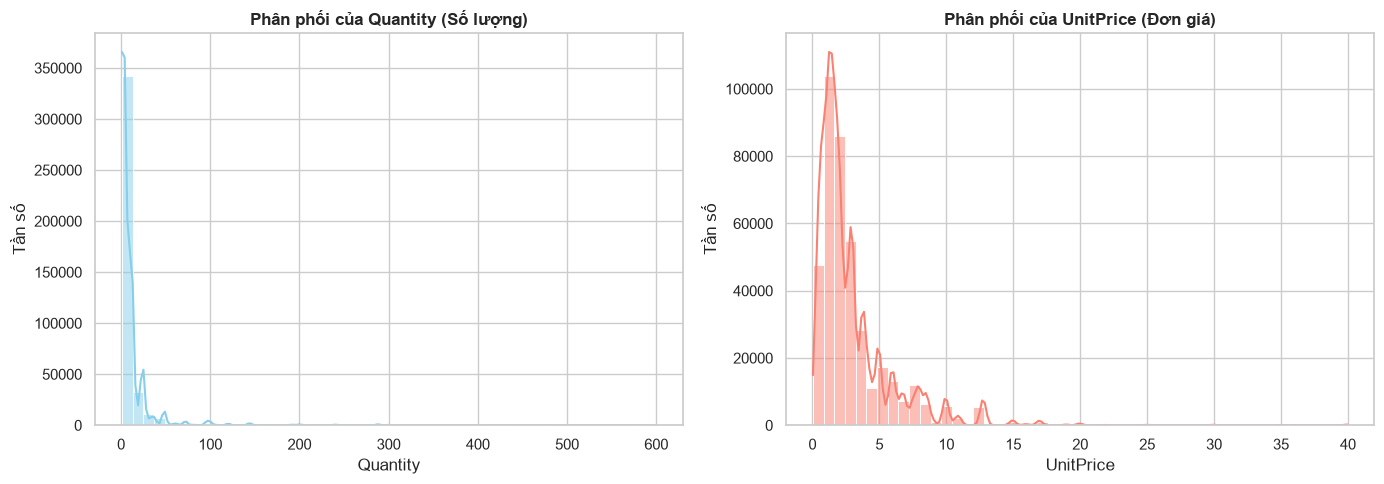

Nhận xét: Hai thuộc tính có xu hướng lệch phải mạnh (extreme right skewness).
Phần lớn các giao dịch tập trung ở lượng nhỏ và đơn giá phổ thông, có đuôi dài về phía giá trị lớn.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Quantity'], kde=True, ax=axes[0], color='skyblue', bins=50)
axes[0].set_title('Phân phối của Quantity (Số lượng)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Quantity')
axes[0].set_ylabel('Tần số')

sns.histplot(df['UnitPrice'], kde=True, ax=axes[1], color='salmon', bins=50)
axes[1].set_title('Phân phối của UnitPrice (Đơn giá)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('UnitPrice')
axes[1].set_ylabel('Tần số')

plt.tight_layout()
plt.show()

print("Nhận xét: Hai thuộc tính có xu hướng lệch phải mạnh (extreme right skewness).")
print("Phần lớn các giao dịch tập trung ở lượng nhỏ và đơn giá phổ thông, có đuôi dài về phía giá trị lớn.")

### 5. Phát hiện ngoại lai (Outliers) bằng Boxplot & Phương pháp khoảng tứ phân vị IQR

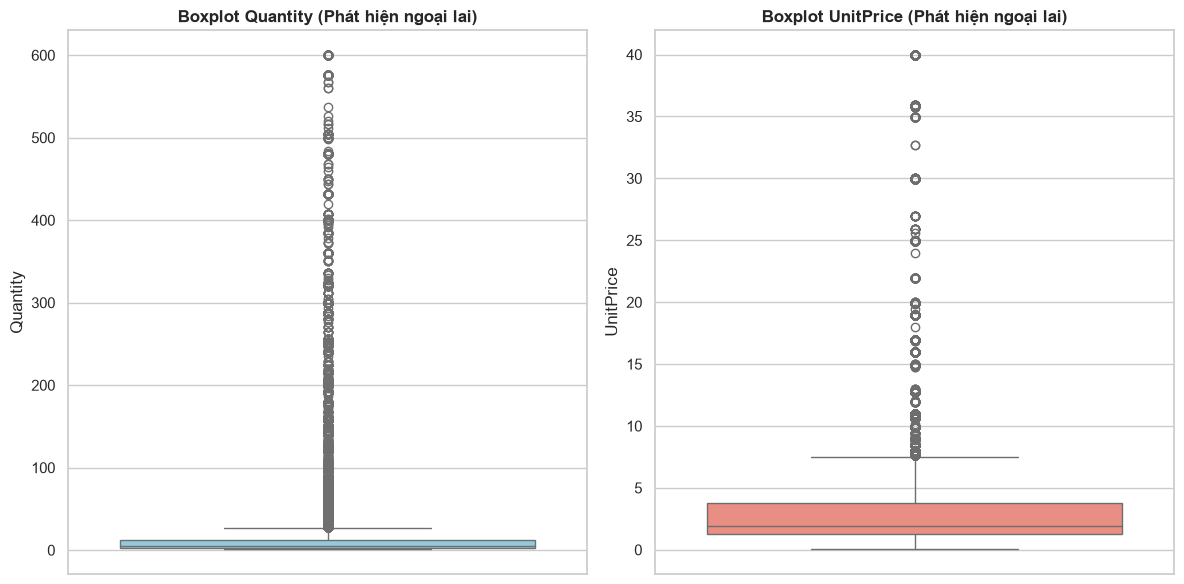

--- KẾT QUẢ ĐO LƯỜNG NGOẠI LAI THEO PHƯƠNG PHÁP IQR ---
  Thuoc_tinh  Q1 (25%)  Trung vi (50%)  Q3 (75%)   IQR  Nguong_duoi  \
0   Quantity      2.00            5.00     12.00  10.0        -13.0   
1  UnitPrice      1.25            1.95      3.75   2.5         -2.5   

   Nguong_tren  So_ngoai_lai  Ty_le_ngoai_lai_%  
0         27.0         25944               6.39  
1          7.5         31722               7.82  


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

sns.boxplot(y=df['Quantity'], ax=axes[0], color='skyblue')
axes[0].set_title("Boxplot Quantity (Phát hiện ngoại lai)", fontsize=12, fontweight='bold')

sns.boxplot(y=df['UnitPrice'], ax=axes[1], color='salmon')
axes[1].set_title("Boxplot UnitPrice (Phát hiện ngoại lai)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Tính toán các ngưỡng thống kê theo IQR
def compute_iqr(series, name):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((series < lower) | (series > upper)).sum()
    return {
        'Thuoc_tinh': name,
        'Q1 (25%)': Q1,
        'Trung vi (50%)': series.median(),
        'Q3 (75%)': Q3,
        'IQR': IQR,
        'Nguong_duoi': lower,
        'Nguong_tren': upper,
        'So_ngoai_lai': n_outliers,
        'Ty_le_ngoai_lai_%': round(n_outliers / len(series) * 100, 2)
    }

iqr_df = pd.DataFrame([
    compute_iqr(df['Quantity'], 'Quantity'),
    compute_iqr(df['UnitPrice'], 'UnitPrice')
])
print("--- KẾT QUẢ ĐO LƯỜNG NGOẠI LAI THEO PHƯƠNG PHÁP IQR ---")
print(iqr_df)

### 6. Phân tích giá trị đơn hàng (TotalPrice) & Ma trận tương quan

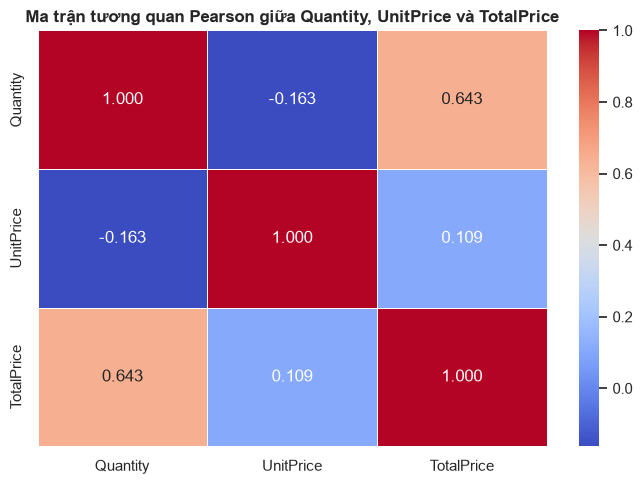

--- MA TRẬN TƯƠNG QUAN ---
            Quantity  UnitPrice  TotalPrice
Quantity    1.000000  -0.162699    0.642577
UnitPrice  -0.162699   1.000000    0.108826
TotalPrice  0.642577   0.108826    1.000000


In [7]:
# Tính tạm TotalPrice
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
corr_matrix = df[['Quantity', 'UnitPrice', 'TotalPrice']].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5, cbar=True)
plt.title('Ma trận tương quan Pearson giữa Quantity, UnitPrice và TotalPrice', fontweight='bold')
plt.tight_layout()
plt.show()

print("--- MA TRẬN TƯƠNG QUAN ---")
print(corr_matrix)

### 7. Phân tích xu hướng doanh thu theo chu kỳ thời gian (Monthly Revenue)

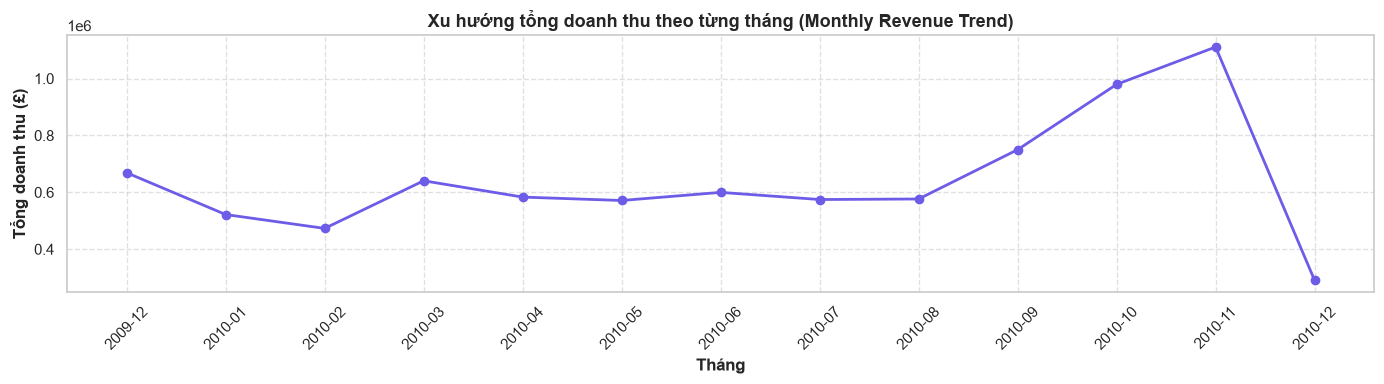

In [8]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df_temp = df.copy()
df_temp['YearMonth'] = df_temp['InvoiceDate'].dt.to_period('M')

monthly_revenue = df_temp.groupby('YearMonth')['TotalPrice'].sum()
monthly_revenue_df = monthly_revenue.reset_index()
monthly_revenue_df['YearMonth'] = monthly_revenue_df['YearMonth'].astype(str)

plt.figure(figsize=(14, 4))
plt.plot(monthly_revenue_df['YearMonth'], monthly_revenue_df['TotalPrice'], 
         marker='o', color='#6c5ce7', linewidth=2, markersize=6)
plt.title('Xu hướng tổng doanh thu theo từng tháng (Monthly Revenue Trend)', fontweight='bold', fontsize=13)
plt.xlabel('Tháng', fontweight='bold')
plt.ylabel('Tổng doanh thu (£)', fontweight='bold')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### 8. Thống kê Top 10 sản phẩm bán chạy nhất và Top 10 thị trường quốc gia

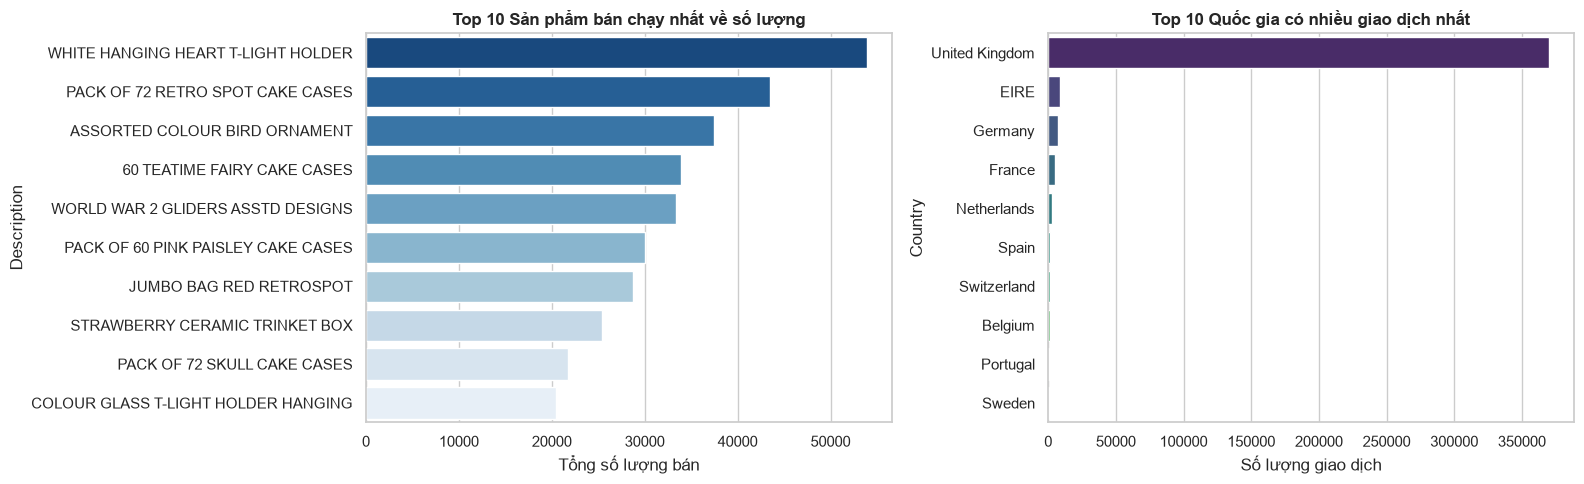

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 sản phẩm
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=top_products.values, y=top_products.index, palette='Blues_r', ax=axes[0], hue=top_products.index, legend=False)
axes[0].set_title('Top 10 Sản phẩm bán chạy nhất về số lượng', fontweight='bold')
axes[0].set_xlabel('Tổng số lượng bán')

# Top 10 quốc gia
top_countries = df['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis', ax=axes[1], hue=top_countries.index, legend=False)
axes[1].set_title('Top 10 Quốc gia có nhiều giao dịch nhất', fontweight='bold')
axes[1].set_xlabel('Số lượng giao dịch')

plt.tight_layout()
plt.show()

### 9. Tổng kết kết quả Khám phá Dữ liệu (EDA)

* **Phân bố địa lý:** Khách hàng tập trung áp đảo ở Vương quốc Anh (United Kingdom) với trên 90% tổng số đơn hàng.
* **Đặc tính sản phẩm:** Sản phẩm đa dạng, nhóm hàng gia dụng và quà lưu niệm có sản lượng tiêu thụ lớn nhất.
* **Đặc tính phân phối:** `Quantity` và `UnitPrice` lệch phải cực mạnh, xuất hiện nhiều đơn hàng bán sỉ quy mô lớn hoặc giá trị ngoại lai cao.
* **Tính toàn vẹn:** Cần xử lý triệt để trùng lặp, lọc bỏ giao dịch không hợp lệ (`Quantity <= 0`, `UnitPrice <= 0`) và chuẩn hóa trường `CustomerID` ở bước Tiền xử lý tiếp theo.

---
## 10. CELL XUẤT TẤT CẢ KẾT QUẢ KHÁM PHÁ (EDA) RA FILE
Cell này tự động xuất toàn bộ các bảng số liệu thống kê, báo cáo tổng hợp và kết quả phân tích khám phá ra thư mục `outputs/`.

In [10]:
# ==============================================================================
# CELL XUẤT TẤT CẢ KẾT QUẢ EDA RA FILE
# ==============================================================================
output_dir = "01_EDA/outputs" if os.path.exists("01_EDA") else "EDA/01_EDA/outputs"
os.makedirs(output_dir, exist_ok=True)

# 1. Xuất bảng thống kê mô tả
desc_stats.to_csv(os.path.join(output_dir, "eda_descriptive_statistics.csv"), encoding="utf-8-sig")

# 2. Xuất bảng kiểm tra tính toàn vẹn (Missing & Duplicates)
integrity_export = missing_df.copy()
integrity_export["So_dong_trung_lap"] = n_duplicates
integrity_export.to_csv(os.path.join(output_dir, "eda_missing_and_duplicates.csv"), index=False, encoding="utf-8-sig")

# 3. Xuất bảng phân tích ngoại lai IQR
iqr_df.to_csv(os.path.join(output_dir, "eda_outliers_iqr.csv"), index=False, encoding="utf-8-sig")

# 4. Xuất ma trận tương quan
corr_matrix.to_csv(os.path.join(output_dir, "eda_correlation_matrix.csv"), encoding="utf-8-sig")

# 5. Xuất doanh thu theo tháng
monthly_revenue_df.to_csv(os.path.join(output_dir, "eda_monthly_revenue.csv"), index=False, encoding="utf-8-sig")

# 6. Xuất Top 10 sản phẩm
top_products_df = top_products.reset_index()
top_products_df.columns = ['Description', 'Total_Quantity']
top_products_df.to_csv(os.path.join(output_dir, "eda_top10_products.csv"), index=False, encoding="utf-8-sig")

# 7. Xuất Top 10 quốc gia
top_countries_df = top_countries.reset_index()
top_countries_df.columns = ['Country', 'Transaction_Count']
top_countries_df.to_csv(os.path.join(output_dir, "eda_top10_countries.csv"), index=False, encoding="utf-8-sig")

# 8. Xuất file báo cáo tóm tắt tổng hợp văn bản
lines_report = [
    "="*80,
    "BÁO CÁO TỔNG HỢP KẾT QUẢ KHÁM PHÁ DỮ LIỆU (EDA SUMMARY REPORT)",
    "Dự án: Phân khúc khách hàng Online Retail II bằng RFM & Machine Learning",
    "="*80,
    "1. THÔNG SỐ TỔNG QUAN TẬP DỮ LIỆU GỐC:",
    f"   - Tổng số dòng giao dịch       : {df.shape[0]:,} dòng",
    f"   - Tổng số cột thuộc tính       : {df.shape[1]} cột",
    f"   - Số dòng trùng lặp hoàn toàn  : {n_duplicates:,} dòng ({n_duplicates/len(df)*100:.2f}%)",
    f"   - Giao dịch thiếu CustomerID   : {df['Customer ID'].isnull().sum():,} dòng",
    "",
    "2. KIỂM TRA GIÁ TRỊ BẤT THƯỜNG:",
    f"   - Quantity âm / bằng 0         : {neg_quantity + zero_quantity:,} dòng",
    f"   - UnitPrice âm / bằng 0        : {neg_unitprice + zero_unitprice:,} dòng",
    f"   - Ngoại lai Quantity (theo IQR): {iqr_df.loc[iqr_df['Thuoc_tinh']=='Quantity', 'So_ngoai_lai'].values[0]:,} dòng ({iqr_df.loc[iqr_df['Thuoc_tinh']=='Quantity', 'Ty_le_ngoai_lai_%'].values[0]}%)",
    f"   - Ngoại lai UnitPrice (theo IQR)   : {iqr_df.loc[iqr_df['Thuoc_tinh']=='UnitPrice', 'So_ngoai_lai'].values[0]:,} dòng ({iqr_df.loc[iqr_df['Thuoc_tinh']=='UnitPrice', 'Ty_le_ngoai_lai_%'].values[0]}%)",
    "",
    "3. HOẠT ĐỘNG KINH DOANH & THỊ TRƯỜNG:",
    f"   - Thị trường lớn nhất          : {top_countries.index[0]} ({top_countries.values[0]:,} giao dịch, {top_countries.values[0]/len(df)*100:.1f}%)",
    f"   - Sản phẩm bán chạy nhất       : {top_products.index[0]} ({top_products.values[0]:,} sản phẩm)",
    f"   - Tháng đạt doanh thu cao nhất : {monthly_revenue_df.iloc[monthly_revenue_df['TotalPrice'].argmax()]['YearMonth']} ({monthly_revenue_df['TotalPrice'].max():,.2f} £)",
    "="*80
]
report_summary = chr(10).join(lines_report)
report_path = os.path.join(output_dir, "eda_summary_report.txt")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report_summary)

print(f"💾 [XUẤT KẾT QUẢ THÀNH CÔNG] Đã lưu 8 tệp kết quả EDA vào thư mục: '{output_dir}'")
for file in sorted(os.listdir(output_dir)):
    fpath = os.path.join(output_dir, file)
    print(f"   ✔ {file} ({os.path.getsize(fpath):,} bytes)")

💾 [XUẤT KẾT QUẢ THÀNH CÔNG] Đã lưu 8 tệp kết quả EDA vào thư mục: '01_EDA/outputs'
   ✔ eda_correlation_matrix.csv (200 bytes)
   ✔ eda_descriptive_statistics.csv (739 bytes)
   ✔ eda_missing_and_duplicates.csv (262 bytes)
   ✔ eda_monthly_revenue.csv (282 bytes)
   ✔ eda_outliers_iqr.csv (207 bytes)
   ✔ eda_summary_report.txt (1,264 bytes)
   ✔ eda_top10_countries.csv (178 bytes)
   ✔ eda_top10_products.csv (415 bytes)


---
## 11. CELL XUẤT TẤT CẢ CÁC ẢNH BIỂU ĐỒ ĐÃ THỂ HIỆN RA FILE
Cell này tự động vẽ lại và lưu tất cả các biểu đồ trực quan của bước khám phá EDA ra file hình ảnh độ phân giải cao (`.png`, 300 DPI) vào thư mục `figures/` của module và đồng bộ vào `figures/` của đề tài.

In [11]:
# ==============================================================================
# CELL XUẤT TẤT CẢ CÁC ẢNH BIỂU ĐỒ EDA RA FILE
# ==============================================================================
local_fig_dir = "01_EDA/figures" if os.path.exists("01_EDA") else "EDA/01_EDA/figures"
root_fig_dir = "figures"
os.makedirs(local_fig_dir, exist_ok=True)
os.makedirs(root_fig_dir, exist_ok=True)

saved_figures = []

def save_both(fig, filename):
    p1 = os.path.join(local_fig_dir, filename)
    p2 = os.path.join(root_fig_dir, filename)
    fig.savefig(p1, dpi=300, bbox_inches='tight')
    fig.savefig(p2, dpi=300, bbox_inches='tight')
    plt.close(fig)
    saved_figures.append(filename)

# 1. Phân phối Quantity và Price
fig1, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Quantity'], kde=True, ax=axes[0], color='skyblue', bins=50)
axes[0].set_title('Phân phối của Quantity (Số lượng)', fontsize=12, fontweight='bold')
sns.histplot(df['UnitPrice'], kde=True, ax=axes[1], color='salmon', bins=50)
axes[1].set_title('Phân phối của UnitPrice (Đơn giá)', fontsize=12, fontweight='bold')
plt.tight_layout()
save_both(fig1, 'fig01_eda_quantity_price_dist.png')

# 2. Boxplot phát hiện ngoại lai
fig2, axes = plt.subplots(1, 2, figsize=(12, 6))
sns.boxplot(y=df['Quantity'], ax=axes[0], color='skyblue')
axes[0].set_title("Boxplot Quantity (Phát hiện ngoại lai)", fontsize=12, fontweight='bold')
sns.boxplot(y=df['UnitPrice'], ax=axes[1], color='salmon')
axes[1].set_title("Boxplot UnitPrice (Phát hiện ngoại lai)", fontsize=12, fontweight='bold')
plt.tight_layout()
save_both(fig2, 'fig02_eda_boxplot_outliers.png')

# 3. Xu hướng doanh thu theo tháng
fig3, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly_revenue_df['YearMonth'], monthly_revenue_df['TotalPrice'], 
        marker='o', color='#6c5ce7', linewidth=2, markersize=6)
ax.set_title('Xu hướng tổng doanh thu theo từng tháng (Monthly Revenue)', fontweight='bold', fontsize=13)
ax.set_xlabel('Tháng', fontweight='bold')
ax.set_ylabel('Tổng doanh thu (£)', fontweight='bold')
plt.xticks(rotation=45)
ax.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
save_both(fig3, 'fig03_eda_monthly_revenue.png')

# 4. Ma trận tương quan Pearson
fig4, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5, cbar=True, ax=ax)
ax.set_title('Ma trận tương quan Pearson giữa Quantity, UnitPrice và TotalPrice', fontweight='bold')
plt.tight_layout()
save_both(fig4, 'fig_eda_correlation_heatmap.png')

# 5. Top 10 sản phẩm bán chạy nhất
fig5, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_products.values, y=top_products.index, palette='Blues_r', ax=ax, hue=top_products.index, legend=False)
ax.set_title('Top 10 Sản phẩm bán chạy nhất về số lượng', fontweight='bold')
ax.set_xlabel('Tổng số lượng bán')
plt.tight_layout()
save_both(fig5, 'fig_eda_top_products.png')

# 6. Top 10 quốc gia có nhiều giao dịch nhất
fig6, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis', ax=ax, hue=top_countries.index, legend=False)
ax.set_title('Top 10 Quốc gia có nhiều giao dịch nhất', fontweight='bold')
ax.set_xlabel('Số lượng giao dịch')
plt.tight_layout()
save_both(fig6, 'fig_eda_top_countries.png')

print(f"🖼️ [XUẤT BIỂU ĐỒ THÀNH CÔNG] Đã lưu {len(saved_figures)} biểu đồ vào:")
print(f"   1. Thư mục module: '{local_fig_dir}'")
print(f"   2. Thư mục gốc  : '{root_fig_dir}'")
for fn in saved_figures:
    p = os.path.join(local_fig_dir, fn)
    print(f"   ✔ {fn} ({os.path.getsize(p):,} bytes)")

🖼️ [XUẤT BIỂU ĐỒ THÀNH CÔNG] Đã lưu 6 biểu đồ vào:
   1. Thư mục module: '01_EDA/figures'
   2. Thư mục gốc  : 'figures'
   ✔ fig01_eda_quantity_price_dist.png (173,020 bytes)
   ✔ fig02_eda_boxplot_outliers.png (140,371 bytes)
   ✔ fig03_eda_monthly_revenue.png (183,544 bytes)
   ✔ fig_eda_correlation_heatmap.png (100,539 bytes)
   ✔ fig_eda_top_products.png (181,144 bytes)
   ✔ fig_eda_top_countries.png (104,498 bytes)
